In [13]:
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.datasets import fetch_openml
from sklearn.feature_selection import (
    SelectKBest, mutual_info_classif, f_classif, RFE, SelectFromModel
)
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import (
    train_test_split, RepeatedStratifiedKFold, StratifiedKFold,
    cross_val_score
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.ensemble import RandomForestClassifier

import app

SEED = 42
print("scikit-learn:", sklearn.__version__)


titanic = fetch_openml("titanic", version=1, as_frame=True)
df = titanic.frame.copy()

df["survived"] = df["survived"].astype(int)

raw_cols = ["age", "fare", "sibsp", "parch", "pclass", "sex", "embarked", "name"]
X = df[raw_cols].copy()
y = df["survived"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED
)
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

print("Rows:", len(df), "| Training:", len(X_tr), "| Test:", len(X_te))
print("Survival rate:", round(y.mean(), 3))

scikit-learn: 1.9.0
Rows: 1309 | Training: 981 | Test: 328
Survival rate: 0.382


In [14]:
df.head()

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"


In [15]:
def engineer_features(data):
    d = data.copy()

    d["family_size"] = d["sibsp"] + d["parch"] + 1
    d["is_alone"] = (d["family_size"] == 1).astype(str)
    d["fare_per_person"] = d["fare"] / d["family_size"].clip(lower=1)
    d["is_child"] = (d["age"] < 16).astype(str)

    d["title"] = (
        d["name"].str.extract(r",\s*([^.]*)\.", expand=False)
        .str.strip()
        .replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
    )
    common = ["Mr", "Miss", "Mrs", "Master"]
    d.loc[~d["title"].isin(common), "title"] = "Rare"


    return d.drop(columns="name")

print("Raw columns:", X_tr.shape[1])
print("Engineered columns:", engineer_features(X_tr).shape[1])

Raw columns: 8
Engineered columns: 12


In [16]:
raw_numeric = ["age", "fare", "sibsp", "parch", "pclass"]
raw_categorical = ["sex", "embarked"]
eng_numeric = raw_numeric + ["family_size", "fare_per_person"]
eng_categorical = raw_categorical + ["is_alone", "is_child", "title"]

def make_preprocessor(engineered=False):
    numeric = eng_numeric if engineered else raw_numeric
    categorical = eng_categorical if engineered else raw_categorical
    return ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scale", StandardScaler())
        ]), numeric),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
        ]), categorical)
    ])

def make_pipeline(engineered=False, selector=None):
    steps = []
    if engineered:
        steps.append(("features", FunctionTransformer(engineer_features, validate=False)))
    steps.append(("preprocess", make_preprocessor(engineered)))
    if selector is not None:
        steps.append(("select", selector))
    steps.append(("model", LogisticRegression(max_iter=3000)))
    return Pipeline(steps)

def cv_auc(model):
    scores = cross_val_score(model, X_tr, y_tr, cv=cv, scoring="roc_auc")
    return scores.mean(), scores.std()

base = make_pipeline(engineered=False)
engineered = make_pipeline(engineered=True)
print("Pipelines are ready.")

Pipelines are ready.


In [17]:
def score_row(name, model, feature_count):
    mean, std = cv_auc(model)
    return {"Feature set": name, "AUC mean": mean, "AUC std": std, "Features": feature_count}

base_feature_count = len(
    base.fit(X_tr, y_tr).named_steps["preprocess"].get_feature_names_out()
)
engineered_feature_count = len(
    engineered.fit(X_tr, y_tr).named_steps["preprocess"].get_feature_names_out()
)

comparison = [
    score_row("Baseline (raw)", base, base_feature_count),
    score_row("Engineered (all)", engineered, engineered_feature_count)
]

summary = pd.DataFrame(comparison).round(4)
display(summary)
print("Difference in mean AUC:", round(summary.loc[1, "AUC mean"] - summary.loc[0, "AUC mean"], 4))

,Feature set,AUC mean,AUC std,Features
0,Baseline (raw),0.8308,0.025,10
1,Engineered (all),0.8407,0.025,21


Difference in mean AUC: 0.0099


In [18]:
selectors = {
    "Filter: mutual information (10)": SelectKBest(mutual_info_classif, k=10),
    "Wrapper: RFE (10)": RFE(
        LogisticRegression(max_iter=3000), n_features_to_select=10
    ),
    "Embedded: L1 logistic regression": SelectFromModel(
        LogisticRegression(l1_ratio=1, solver="liblinear", C=0.5, max_iter=3000)
    ),
    "Embedded: random-forest importance": SelectFromModel(
        RandomForestClassifier(n_estimators=200, random_state=SEED), threshold="median"
    )
}

selection_rows = []
selection_pipelines = {}
for name, selector in selectors.items():
    pipe = make_pipeline(engineered=True, selector=selector)
    mean, std = cv_auc(pipe)
    fitted = pipe.fit(X_tr, y_tr)
    kept = int(fitted.named_steps["select"].get_support().sum())
    selection_pipelines[name] = pipe
    selection_rows.append({
        "Feature set": name, "AUC mean": mean, "AUC std": std, "Features": kept
    })

selection_summary = pd.concat([summary, pd.DataFrame(selection_rows)], ignore_index=True).round(4)
display(selection_summary.sort_values("AUC mean", ascending=False))

,Feature set,AUC mean,AUC std,Features
1,Engineered (all),0.8407,0.0250,21
4,Embedded: L1 logistic regression,0.8400,0.0251,16
5,Embedded: random-forest importance,0.8378,0.0270,11
3,Wrapper: RFE (10),0.8339,0.0224,10
0,Baseline (raw),0.8308,0.0250,10
2,Filter: mutual information (10),0.8232,0.0257,10


Held-out engineered AUC: 0.8773


,mean AUC decrease
sex,0.0942
pclass,0.0626
name,0.0493
sibsp,0.0235
parch,0.0045
age,0.0036
fare,0.0007
embarked,-0.0003


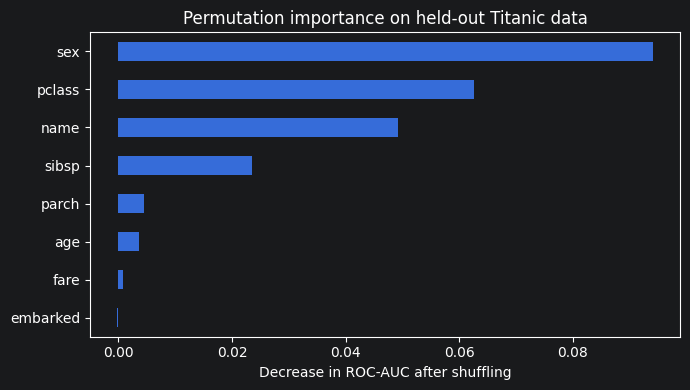

In [19]:
final_model = engineered.fit(X_tr, y_tr)
test_prob = final_model.predict_proba(X_te)[:, 1]
print("Held-out engineered AUC:", round(roc_auc_score(y_te, test_prob), 4))

perm = permutation_importance(
    final_model, X_te, y_te, scoring="roc_auc",
    n_repeats=20, random_state=SEED
)
importance = pd.Series(perm.importances_mean, index=X_te.columns).sort_values(ascending=False)
display(importance.to_frame("mean AUC decrease").round(4))

importance.sort_values().plot.barh(figsize=(7, 4), title="Permutation importance on held-out Titanic data")
plt.xlabel("Decrease in ROC-AUC after shuffling")
plt.tight_layout()
plt.show()

In [20]:
rng = np.random.RandomState(SEED)
X_noise = rng.randn(100, 2000)
y_noise = rng.randint(0, 2, 100)
noise_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

X_selected_wrong = SelectKBest(f_classif, k=20).fit_transform(X_noise, y_noise)
wrong = cross_val_score(
    LogisticRegression(max_iter=2000), X_selected_wrong, y_noise,
    cv=noise_cv, scoring="accuracy"
).mean()

safe_noise = Pipeline([
    ("select", SelectKBest(f_classif, k=20)),
    ("model", LogisticRegression(max_iter=2000))
])
right = cross_val_score(
    safe_noise, X_noise, y_noise, cv=noise_cv, scoring="accuracy"
).mean()

print(f"Selection outside CV (wrong): {wrong:.3f}")
print(f"Selection inside Pipeline (right): {right:.3f}")
print("The safe score should be near chance (0.50) on random labels.")

Selection outside CV (wrong): 0.780
Selection inside Pipeline (right): 0.360
The safe score should be near chance (0.50) on random labels.


In [21]:
probe = make_pipeline(engineered=True).fit(X_tr, y_tr)
processed_names = probe.named_steps["preprocess"].get_feature_names_out()

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
counts = pd.Series(0, index=processed_names, dtype=float)
stability_selector = SelectFromModel(
    LogisticRegression(l1_ratio=1, solver="liblinear", C=0.5, max_iter=3000)
)

for train_idx, _ in folds.split(X_tr, y_tr):
    fold_pipe = make_pipeline(engineered=True, selector=clone(stability_selector))
    fold_pipe.fit(X_tr.iloc[train_idx], y_tr.iloc[train_idx])
    kept = processed_names[fold_pipe.named_steps["select"].get_support()]
    counts.loc[kept] += 1

stability = (counts / folds.get_n_splits()).sort_values(ascending=False)
display(stability.head(15).to_frame("selection frequency").round(2))

,selection frequency
num__age,1.0
num__fare,1.0
num__sibsp,1.0
num__pclass,1.0
num__family_size,1.0
cat__title_Mr,1.0
cat__sex_female,1.0
cat__sex_male,1.0
cat__embarked_C,1.0
cat__title_Master,1.0


In [22]:
import joblib
joblib.dump(final_model, "titanic_engineered_pipeline.joblib")
print("Saved titanic_engineered_pipeline.joblib")

Saved titanic_engineered_pipeline.joblib
